<a href="https://colab.research.google.com/github/crovillo/DS3000-AI-vs-Human-Detection-/blob/main/DS3000_AIvsHumanDetection_Group13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS3000: AI vs HumanDetection #
## Group 13 ##

| Member | Contributions |
|---|---|
| Name 1 | |
| Name 2 | |
| Name 3 | |
| Name 4 | |

## 1. Dataset Loading

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
np.random.seed(SEED)

In [ ]:
import kagglehub, glob, os

path = kagglehub.dataset_download("pratyushpuri/ai-vs-human-content-detection-1000-record-in-2025")
csv_file = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)[0]
print(csv_file)

100%|██████████| 519k/519k [00:00<00:00, 589kB/s]

Extracting files...
/root/.cache/kagglehub/datasets/pratyushpuri/ai-vs-human-content-detection-1000-record-in-2025/versions/1/ai_human_content_detection_dataset.csv


In [ ]:
df = pd.read_csv(csv_file)
print(df.shape)
df.head()

(1367, 17)


,text_content,content_type,word_count,character_count,sentence_count,lexical_diversity,avg_sentence_length,avg_word_length,punctuation_ratio,flesch_reading_ease,gunning_fog_index,grammar_errors,passive_voice_ratio,predictability_score,burstiness,sentiment_score,label
0,Score each cause. Quality throughout beautiful...,academic_paper,288,1927,54,0.9514,5.33,5.69,0.0280,53.08,7.41,1,0.1041,105.86,0.5531,0.2034,1
1,Board its rock. Job worker break tonight coupl...,essay,253,1719,45,0.9723,5.62,5.80,0.0262,50.32,8.10,6,0.2045,100.29,0.5643,0.4854,1
2,Way debate decision produce. Dream necessary c...,academic_paper,420,2849,75,0.9071,5.60,5.79,0.0263,46.86,7.86,5,0.2308,96.88,0.4979,-0.2369,1
3,Story turn because such during open model. Tha...,creative_writing,196,1310,34,0.9592,5.76,5.69,0.0260,53.80,7.00,2,0.1912,88.79,0.6241,NaN,1
4,Place specific as simply leader fall analysis....,news_article,160,1115,28,0.9688,5.71,5.97,0.0251,44.53,8.29,0,0.1318,26.15,0.2894,NaN,1


# 2. Problem Statement

Can we tell whether a piece of text is AI generated or made by a human.

## 3. Date Audit and Cleaning

In [ ]:
audit = pd.DataFrame({
    "type": df.dtypes,
    "missing": df.isna().sum(),
    "% missing": (df.isna().mean() * 100).round(2),
    "unique values": df.nunique(),
})
audit

,type,missing,% missing,unique values
text_content,object,0,0.00,1367
content_type,object,0,0.00,8
word_count,int64,0,0.00,359
character_count,int64,0,0.00,974
sentence_count,int64,0,0.00,82
lexical_diversity,float64,0,0.00,522
avg_sentence_length,float64,0,0.00,166
avg_word_length,float64,0,0.00,152
punctuation_ratio,float64,0,0.00,145
flesch_reading_ease,float64,79,5.78,984


In [ ]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate texts:", df["text_content"].duplicated().sum())
print("\nTarget Balance:\n", df["label"].value_counts())
print("\nContent Types:\n", df["content_type"].value_counts())

Duplicate rows: 0
Duplicate texts: 0

Target Balance:
 label
0    684
1    683
Name: count, dtype: int64

Content Types:
 content_type
academic_paper      189
news_article        185
blog_post           183
creative_writing    172
article             171
essay               161
social_media        154
product_review      152
Name: count, dtype: int64


In [ ]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
word_count,1367.0,140.191,97.410,3.000,61.500,131.000,193.000,443.000
character_count,1367.0,940.329,654.335,14.000,410.500,882.000,1294.500,2966.000
sentence_count,1367.0,25.610,17.867,1.000,11.000,24.000,35.000,83.000
lexical_diversity,1367.0,0.968,0.026,0.875,0.952,0.969,0.989,1.000
avg_sentence_length,1367.0,5.486,0.447,3.000,5.270,5.480,5.700,8.000
avg_word_length,1367.0,5.718,0.280,4.000,5.590,5.710,5.830,8.330
punctuation_ratio,1367.0,0.027,0.003,0.019,0.026,0.027,0.028,0.071
flesch_reading_ease,1288.0,52.183,10.467,-50.010,47.712,52.190,57.323,98.870
gunning_fog_index,1332.0,7.557,1.867,1.200,6.620,7.515,8.390,27.870
grammar_errors,1367.0,1.538,1.912,0.000,0.000,1.000,3.000,10.000


The value ranges look valid, there are no negative countsm ratios are within 0 and 1, and sentiment is within -1 and 1. A few extreme readability scores (Flesch min of -50, Gunning Fog max 27.9) are possible for very complex texts, so we can keep these instead of remove them. "label" has a mean of 0.5, so the classes are balanced.

## 4. Exploratory Data Analysis (EDA)

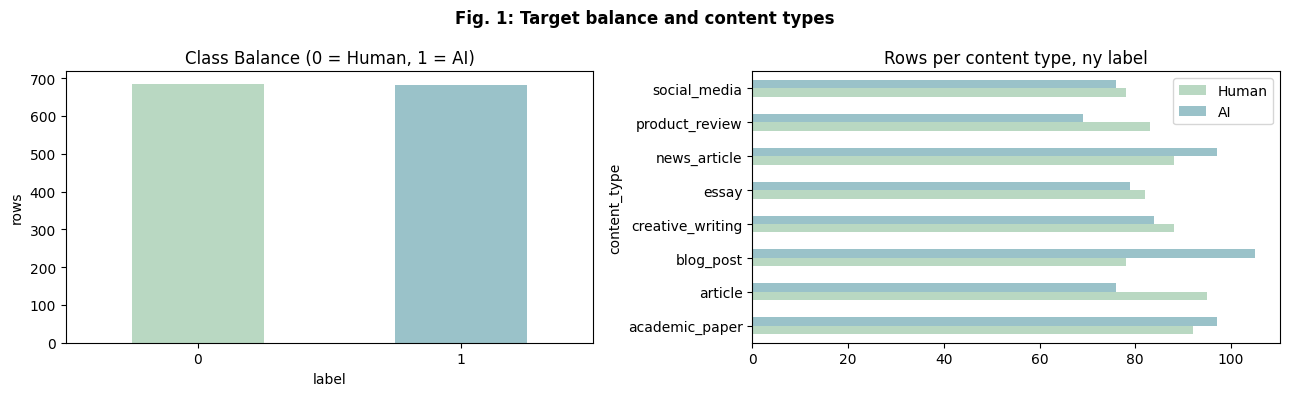

In [10]:
fig, axes = plt.subplots(1, 2, figsize = (13, 4))

df["label"].value_counts().plot.bar(ax = axes[0], color = ["#B9D8C2", "#9AC2C9"], rot = 0)
axes[0].set_title("Class Balance (0 = Human, 1 = AI)")
axes[0].set_ylabel("rows")

pd.crosstab(df["content_type"], df["label"]).plot.barh(ax = axes[1], color = ["#B9D8C2", "#9AC2C9"])
axes[1].set_title("Rows per content type, ny label")
axes[1].legend(["Human", "AI"])

plt.suptitle("Fig. 1: Target balance and content types", fontweight = "bold")
plt.tight_layout()
plt.show()